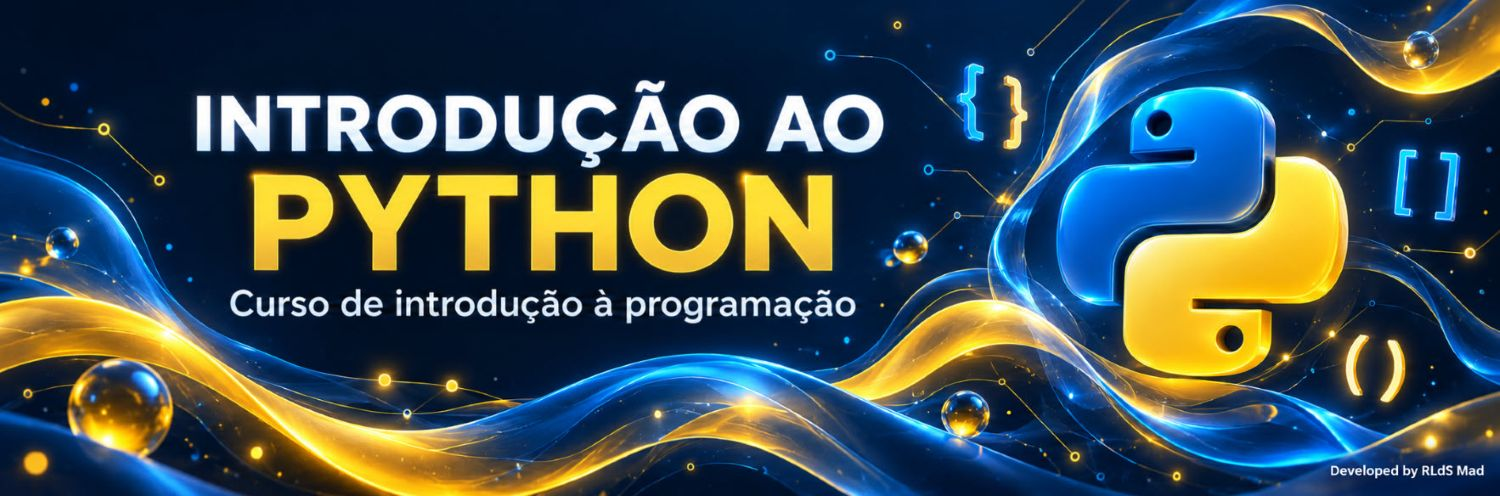

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_3_ia/N3_07_Texto_NLP.ipynb)


# Nível IA · Módulo 7 – Texto e linguagem natural
## Do saco de palavras aos *transformers*

Grande parte da informação do mundo está em **texto**: avaliações de clientes, emails, relatórios, notícias, documentos legais. O **processamento de linguagem natural** (PLN, ou NLP, *natural language processing*) ensina os computadores a trabalhar com ele: classificar, pesquisar, resumir, traduzir, responder.

O problema de partida é que os algoritmos só trabalham com **números**. Este módulo segue a evolução das formas de transformar texto em números, da mais simples à mais poderosa: contar palavras (***bag-of-words***), pesá-las pela raridade (**TF-IDF**), aprender vetores densos com significado (***embeddings***) e, por fim, os ***transformers***, a arquitetura por trás dos grandes modelos de linguagem.

O caso de estudo volta à loja dos módulos N3_03 e N3_05: **classificar avaliações de clientes como positivas ou negativas** (análise de sentimento).

> **Objetivos:** preparar texto (minúsculas, tokenização, *stopwords*) e perceber o efeito de cada decisão; representar textos com *bag-of-words* e TF-IDF, à mão e com o scikit-learn; usar n-gramas para captar negações; classificar sentimento com regressão logística e interpretar os pesos; perceber o que é um *embedding* e treinar um com PyTorch; conhecer a ideia dos *transformers* e usar um modelo pré-treinado (opcional, com Internet).

**Pré-requisitos:** expressões e métodos de texto (capítulo 6), dicionários (capítulo 14), `Counter` e geradores (capítulos 14 e 25), classificação com scikit-learn (N2_04), PyTorch (N3_05).

| Secção | Tema |
| --- | --- |
| 0. Preparação | bibliotecas |
| 1. Texto como dados | o corpus de avaliações |
| 2. Pré-processamento | minúsculas, *tokens* e *stopwords* |
| 3. *Bag-of-words* | contar palavras, à mão e com `CountVectorizer` |
| 4. TF-IDF | pesar as palavras pela raridade |
| 5. Classificar sentimento | regressão logística, n-gramas, interpretação e erros |
| 6. *Embeddings* | vetores densos aprendidos com PyTorch |
| 7. Opcional: *transformers* | atenção, *tokens* e um modelo pré-treinado |
| 8. Experimenta | três exercícios com solução |


## 0. Preparação


In [1]:
# Executar esta célula

import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from torch import nn

plt.rcParams.update({"figure.dpi": 100})
pd.set_option("display.max_colwidth", 120)
torch.manual_seed(0)
print(f"pandas {pd.__version__} | PyTorch {torch.__version__}")

pandas 3.0.6 | PyTorch 2.15.0+cu132


## 1. Texto como dados

### 1.1 O corpus

Um conjunto de textos chama-se **corpus**. A célula seguinte gera 2000 avaliações de clientes da loja, em português, cada uma com um rótulo: 1 (positiva) ou 0 (negativa). As avaliações são **sintéticas**, construídas a partir de modelos de frases, para o notebook funcionar sem Internet; algumas soam um pouco artificiais, mas têm as dificuldades das avaliações reais:
- **negações** («a entrega não foi boa» é negativa, mas tem a palavra «boa»);
- avaliações **mistas** («o produto é ótimo, mas o preço é péssimo»), em que o sentimento depende do equilíbrio;
- **ruído**: cerca de 3 % dos rótulos estão errados, como acontece quando são os próprios clientes a escolher as estrelas.

Tal como no N3_03, não precisas de perceber o gerador para seguir o módulo.


In [2]:
# Executar esta célula

import numpy as np
import pandas as pd

rng = np.random.default_rng(2025)

ASPETOS = {
    "o produto": "m", "a entrega": "f", "a qualidade": "f", "o preço": "m", "o atendimento": "m",
    "a embalagem": "f", "o tamanho": "m", "a aplicação": "f", "o material": "m", "a loja": "f",
}
POS = {"m": ["bom", "ótimo", "excelente", "fantástico", "impecável", "perfeito"],
       "f": ["boa", "ótima", "excelente", "fantástica", "impecável", "perfeita"]}
NEG = {"m": ["mau", "péssimo", "horrível", "fraco", "terrível", "dececionante"],
       "f": ["má", "péssima", "horrível", "fraca", "terrível", "dececionante"]}
INTENS = ["", "", "muito ", "bastante ", "mesmo "]
FRASES_POS = ["adorei", "recomendo", "voltarei a comprar", "chegou rápido", "superou as expectativas",
              "vale cada cêntimo", "estou muito satisfeito", "cinco estrelas", "tudo correu bem"]
FRASES_NEG = ["não recomendo", "nunca mais compro", "chegou atrasado", "veio partido",
              "uma desilusão", "estou arrependido", "dinheiro mal gasto", "pedi reembolso", "foi uma perda de tempo"]
NEUTRAS = ["comprei para oferecer", "encomendei na semana passada", "é a segunda vez que compro",
           "usei durante um mês", "comprei na promoção", "vi a publicidade na internet"]


def frase_aspeto(polaridade):
    asp, g = list(ASPETOS.items())[rng.integers(len(ASPETOS))]
    verbo = rng.choice(["é", "está", "foi"])
    r = rng.random()
    if r < 0.25:                                           # negação: inverte a polaridade
        adj = rng.choice(POS[g] if polaridade < 0 else NEG[g])
        return f"{asp} não {verbo} {adj}", polaridade
    adj = rng.choice(POS[g] if polaridade > 0 else NEG[g])
    return f"{asp} {verbo} {rng.choice(INTENS)}{adj}", polaridade


def avaliacao():
    sentimento = 1 if rng.random() < 0.5 else -1
    partes, total = [], 0.0
    if rng.random() < 0.4:
        partes.append(str(rng.choice(NEUTRAS)))
    for _ in range(rng.integers(1, 4)):
        pol = sentimento if rng.random() < 0.8 else -sentimento           # às vezes, um aspeto contrário
        if rng.random() < 0.55:
            texto, p = frase_aspeto(pol)
        else:
            texto, p = str(rng.choice(FRASES_POS if pol > 0 else FRASES_NEG)), pol
        partes.append(texto)
        total += p
    if total == 0:                                          # empate: acrescenta uma frase que desempata
        texto_extra, p = frase_aspeto(sentimento) if rng.random() < 0.5 else (
            str(rng.choice(FRASES_POS if sentimento > 0 else FRASES_NEG)), sentimento)
        partes.append(texto_extra)
        total += p
    texto = partes[0]
    for parte in partes[1:]:
        ligacao = rng.choice([", ", ". ", " e ", ", mas "])
        texto += ligacao + (parte[0].upper() + parte[1:] if ligacao == ". " else parte)
    texto = texto[0].upper() + texto[1:] + rng.choice([".", "!", ".", "..."])
    rotulo = int(total > 0)
    if rng.random() < 0.03:                                 # ruído: rótulos errados, como na vida real
        rotulo = 1 - rotulo
    return texto, rotulo


dados = pd.DataFrame([avaliacao() for _ in range(2000)], columns=["texto", "positiva"])

print(f"{len(dados)} avaliações | {dados['positiva'].mean():.0%} positivas")
dados.sample(8, random_state=1)

2000 avaliações | 51% positivas


,texto,positiva
674,A qualidade foi muito perfeita...,1
1699,"A qualidade está bastante ótima, a entrega foi fantástica.",1
1282,"Adorei. Foi uma perda de tempo, o atendimento é muito bom...",1
1315,"É a segunda vez que compro, o produto foi bastante péssimo. Dinheiro mal gasto, uma desilusão...",0
1210,Usei durante um mês. Chegou rápido.,1
1636,"Comprei para oferecer, mas o tamanho não está dececionante.",1
613,"Comprei na promoção, a entrega foi má.",0
447,Foi uma perda de tempo e foi uma perda de tempo...,0


### 1.2 Explorar

Antes de modelar, olha-se para os dados (fase de seleção do KDD, N3_03): tamanho dos textos e palavras mais frequentes.


In [3]:
# Executar esta célula

palavras_por_texto = dados["texto"].str.split().str.len()
print("Palavras por avaliação:", palavras_por_texto.describe().round(1).to_dict())

contagem = Counter(palavra for texto in dados["texto"] for palavra in texto.lower().split())
print("\nAs 15 palavras mais frequentes:")
print(contagem.most_common(15))

Palavras por avaliação: {'count': 2000.0, 'mean': 10.2, 'std': 4.7, 'min': 1.0, '25%': 7.0, '50%': 10.0, '75%': 14.0, 'max': 22.0}

As 15 palavras mais frequentes:
[('a', 1532), ('o', 1195), ('é', 918), ('foi', 892), ('está', 765), ('mas', 746), ('e', 738), ('não', 649), ('muito', 488), ('na', 418), ('bastante', 366), ('mesmo', 336), ('comprei', 273), ('atendimento', 259), ('produto', 252)]


As palavras mais frequentes são artigos, verbos auxiliares e a pontuação colada às palavras («bom.» e «bom» contam como diferentes). Dizem pouco sobre o sentimento. É por isso que o texto precisa de ser **preparado**.

Separamos já treino (75 %) e teste (25 %), estratificando pelo rótulo: tudo o que for aprendido com os textos (o vocabulário, os pesos do TF-IDF) é aprendido só com o treino.


In [4]:
# Executar esta célula

X_treino, X_teste, y_treino, y_teste = train_test_split(
    dados["texto"], dados["positiva"], test_size=0.25, stratify=dados["positiva"], random_state=42)
print(f"Treino: {len(X_treino)} | teste: {len(X_teste)}")

Treino: 1500 | teste: 500


## 2. Pré-processamento

### 2.1 Minúsculas e *tokens*

**Tokenizar** é partir o texto em unidades, os ***tokens***: aqui, palavras. Uma expressão regular simples resolve: `\w+` apanha sequências de letras e algarismos (incluindo as acentuadas) e deixa de fora a pontuação. Pôr tudo em **minúsculas** faz com que «Adorei» e «adorei» sejam o mesmo *token*.


In [5]:
# Executar esta célula

def tokenizar(texto: str) -> list[str]:
    return re.findall(r"\w+", texto.lower())


exemplo = dados["texto"].iloc[3]
print("Texto:  ", exemplo)
print("Tokens: ", tokenizar(exemplo))

Texto:   Vi a publicidade na internet. Cinco estrelas, a qualidade foi mesmo excelente!
Tokens:  ['vi', 'a', 'publicidade', 'na', 'internet', 'cinco', 'estrelas', 'a', 'qualidade', 'foi', 'mesmo', 'excelente']


### 2.2 *Stopwords*: cuidado com o «não»

As ***stopwords*** são palavras muito frequentes e com pouco significado próprio (artigos, preposições, conjunções), que muitas vezes se removem. Mas a lista tem de ser escolhida **para o problema**: as listas habituais de *stopwords* em português incluem «não», e removê-lo transforma «não é bom» em «bom». Em análise de sentimento, isso é desastroso. Vamos usar uma lista curta, feita à mão, **sem** o «não» e o «mas».


In [6]:
# Executar esta célula

STOPWORDS = {"o", "a", "os", "as", "um", "uma", "e", "de", "do", "da", "em", "no", "na", "para", "que", "foi",
             "é", "está", "vez", "me", "se", "com", "por", "ao", "à"}


def preparar(texto: str) -> list[str]:
    return [t for t in tokenizar(texto) if t not in STOPWORDS]


print(preparar(exemplo))
contagem_limpa = Counter(t for texto in X_treino for t in preparar(texto))
print("\nMais frequentes depois de preparar:", contagem_limpa.most_common(12))

['vi', 'publicidade', 'internet', 'cinco', 'estrelas', 'qualidade', 'mesmo', 'excelente']

Mais frequentes depois de preparar: [('mas', 548), ('não', 481), ('muito', 362), ('bastante', 277), ('mesmo', 255), ('comprei', 202), ('atendimento', 194), ('produto', 189), ('loja', 176), ('compro', 176), ('qualidade', 173), ('tamanho', 171)]


Agora as palavras frequentes já dizem alguma coisa. Há outros passos possíveis, como reduzir as palavras à raiz (***stemming***: «recomendo», «recomendado» → «recomend») ou à forma do dicionário (**lematização**). Cada passo é uma **decisão** que pode ajudar ou prejudicar, e deve ser testado (exercício 1).


## 3. *Bag-of-words*: contar palavras

### 3.1 À mão

A representação mais simples de um texto é o ***bag-of-words*** (saco de palavras): constrói-se um **vocabulário** com todas as palavras do corpus, e cada texto passa a ser um vetor com **quantas vezes aparece cada palavra**. A ordem perde-se: o texto é tratado como um saco onde as palavras foram baralhadas.


In [7]:
# Executar esta célula

mini_corpus = ["o produto é bom", "o produto não é bom", "entrega rápida e produto bom"]

vocabulario = sorted({t for texto in mini_corpus for t in tokenizar(texto)})
indice = {palavra: i for i, palavra in enumerate(vocabulario)}
matriz = np.zeros((len(mini_corpus), len(vocabulario)), dtype=int)
for linha, texto in enumerate(mini_corpus):
    for t in tokenizar(texto):
        matriz[linha, indice[t]] += 1

pd.DataFrame(matriz, columns=vocabulario, index=mini_corpus)

,bom,e,entrega,não,o,produto,rápida,é
o produto é bom,1,0,0,0,1,1,0,1
o produto não é bom,1,0,0,1,1,1,0,1
entrega rápida e produto bom,1,1,1,0,0,1,1,0


### 3.2 Com `CountVectorizer`

O scikit-learn faz o mesmo com o `CountVectorizer`: `fit` aprende o vocabulário, `transform` conta. O resultado é uma **matriz esparsa** (*sparse*): como cada texto só usa uma pequena parte do vocabulário, guardam-se só os valores diferentes de zero.


In [8]:
# Executar esta célula

contador = CountVectorizer(token_pattern=r"\w+")
print("Igual à nossa?", np.array_equal(contador.fit_transform(mini_corpus).toarray(), matriz))

bow_treino = contador.fit_transform(X_treino)
print(f"Matriz do treino: {bow_treino.shape} (textos × palavras do vocabulário)")
print(f"Valores diferentes de zero: {bow_treino.nnz} de {np.prod(bow_treino.shape)} "
      f"({bow_treino.nnz / np.prod(bow_treino.shape):.1%}): por isso se guarda em formato esparso")

Igual à nossa? True
Matriz do treino: (1500, 94) (textos × palavras do vocabulário)
Valores diferentes de zero: 13992 de 141000 (9.9%): por isso se guarda em formato esparso


### 3.3 O que o saco de palavras não vê

Como a ordem se perde, textos com significados **opostos** podem ter exatamente o mesmo vetor:


In [9]:
# Executar esta célula

a, b = "não é bom, é mau", "não é mau, é bom"
va, vb = contador.transform([a]).toarray(), contador.transform([b]).toarray()
print(f"«{a}» e «{b}»: mesmo vetor? {np.array_equal(va, vb)}")

«não é bom, é mau» e «não é mau, é bom»: mesmo vetor? True


Uma solução parcial são os **n-gramas**: além das palavras soltas (unigramas), contam-se também os **pares** de palavras seguidas (bigramas, como «não é» e «é bom») ou trios (trigramas). Assim, alguma ordem local é preservada. O custo é um vocabulário muito maior.


In [10]:
# Executar esta célula

for n in [1, 2, 3]:
    v = CountVectorizer(token_pattern=r"\w+", ngram_range=(1, n)).fit(X_treino)
    print(f"ngram_range=(1, {n}): vocabulário com {len(v.vocabulary_):>5} entradas")

bigramas = CountVectorizer(token_pattern=r"\w+", ngram_range=(1, 2)).fit([a, b])
print(f"\nCom bigramas, «{a}» e «{b}» têm o mesmo vetor?",
      np.array_equal(bigramas.transform([a]).toarray(), bigramas.transform([b]).toarray()))

ngram_range=(1, 1): vocabulário com    94 entradas
ngram_range=(1, 2): vocabulário com   838 entradas


ngram_range=(1, 3): vocabulário com  3535 entradas

Com bigramas, «não é bom, é mau» e «não é mau, é bom» têm o mesmo vetor? False


## 4. TF-IDF: pesar as palavras pela raridade

Contar palavras dá o mesmo peso a «produto», que aparece em centenas de avaliações, e a «reembolso», que aparece em poucas mas diz muito. O **TF-IDF** corrige isso multiplicando duas partes:

- **TF** (*term frequency*): quantas vezes a palavra aparece **neste** texto;
- **IDF** (*inverse document frequency*): quão **rara** é a palavra no corpus. No scikit-learn: $\text{idf}(t) = \ln\frac{1 + n}{1 + \text{df}(t)} + 1$, onde $n$ é o número de textos e $\text{df}(t)$ o número de textos que contêm $t$.

No fim, cada vetor é dividido pelo seu comprimento (norma L2), para que textos longos e curtos fiquem comparáveis. Calculamos à mão no mini-corpus e comparamos com o `TfidfVectorizer`:


In [11]:
# Executar esta célula

n = len(mini_corpus)
df = (matriz > 0).sum(axis=0)                          # em quantos textos aparece cada palavra
idf = np.log((1 + n) / (1 + df)) + 1
tfidf_mao = matriz * idf
tfidf_mao = tfidf_mao / np.linalg.norm(tfidf_mao, axis=1, keepdims=True)

tfidf = TfidfVectorizer(token_pattern=r"\w+")
print("Igual ao TfidfVectorizer?", np.allclose(tfidf.fit_transform(mini_corpus).toarray(), tfidf_mao))
pd.DataFrame(tfidf_mao.round(2), columns=vocabulario, index=mini_corpus)

Igual ao TfidfVectorizer? True


,bom,e,entrega,não,o,produto,rápida,é
o produto é bom,0.43,0.00,0.00,0.00,0.56,0.43,0.00,0.56
o produto não é bom,0.35,0.00,0.00,0.59,0.45,0.35,0.00,0.45
entrega rápida e produto bom,0.31,0.52,0.52,0.00,0.00,0.31,0.52,0.00


Repara: «produto» e «bom», que aparecem em todos os textos, têm pesos baixos; «não», «entrega» e «rápida», que só aparecem num, ficam com pesos altos. No corpus completo, as palavras com IDF mais alto e mais baixo são:


In [12]:
# Executar esta célula

tfidf = TfidfVectorizer(token_pattern=r"\w+").fit(X_treino)
idf_serie = pd.Series(tfidf.idf_, index=tfidf.get_feature_names_out()).sort_values()
print("IDF mais baixo (palavras comuns):", idf_serie.head(8).round(2).to_dict())
print("IDF mais alto (palavras raras):  ", idf_serie.tail(8).round(2).to_dict())

IDF mais baixo (palavras comuns): {'a': 1.56, 'o': 1.74, 'é': 1.98, 'foi': 1.99, 'está': 2.08, 'mas': 2.14, 'e': 2.16, 'não': 2.25}
IDF mais alto (palavras raras):   {'ótimo': 4.09, 'arrependido': 4.12, 'pedi': 4.14, 'reembolso': 4.14, 'boa': 4.17, 'péssima': 4.19, 'péssimo': 4.22, 'perfeita': 4.32}


## 5. Classificar o sentimento

### 5.1 Comparar representações

Com os textos transformados em vetores, qualquer classificador do scikit-learn serve. A **regressão logística** é a escolha clássica para texto: rápida, funciona bem com milhares de atributos esparsos e é interpretável. Juntamos o vetorizador e o modelo num `Pipeline` (N2_04), para que o vocabulário seja aprendido só com o treino.


In [13]:
# Executar esta célula

modelos = {
    "referência (classe mais frequente)": make_pipeline(CountVectorizer(), DummyClassifier()),
    "bag-of-words": make_pipeline(CountVectorizer(token_pattern=r"\w+"), LogisticRegression(C=10, max_iter=2000)),
    "TF-IDF (palavras)": make_pipeline(TfidfVectorizer(token_pattern=r"\w+"), LogisticRegression(C=10, max_iter=2000)),
    "TF-IDF + bigramas": make_pipeline(TfidfVectorizer(token_pattern=r"\w+", ngram_range=(1, 2)),
                                       LogisticRegression(C=10, max_iter=2000)),
    "TF-IDF + trigramas": make_pipeline(TfidfVectorizer(token_pattern=r"\w+", ngram_range=(1, 3)),
                                        LogisticRegression(C=10, max_iter=2000)),
    "TF-IDF + trigramas + stopwords": make_pipeline(
        TfidfVectorizer(token_pattern=r"\w+", ngram_range=(1, 3), stop_words=sorted(STOPWORDS)),
        LogisticRegression(C=10, max_iter=2000)),
}
exatidoes = {}
for nome, modelo in modelos.items():
    exatidoes[nome] = modelo.fit(X_treino, y_treino).score(X_teste, y_teste)
    print(f"{nome:<36} exatidão no teste: {exatidoes[nome]:.1%}")

referência (classe mais frequente)   exatidão no teste: 51.0%


bag-of-words                         exatidão no teste: 83.6%


TF-IDF (palavras)                    exatidão no teste: 84.6%


TF-IDF + bigramas                    exatidão no teste: 83.6%


TF-IDF + trigramas                   exatidão no teste: 89.0%


TF-IDF + trigramas + stopwords       exatidão no teste: 95.6%


Três lições:
- **a contagem e o TF-IDF** dão resultados parecidos neste corpus de frases curtas; em textos reais mais longos e variados, o TF-IDF costuma ajudar mais;
- **os bigramas sozinhos não chegam**: «não é bom» dá os bigramas «não é» e «é bom», e «é bom» puxa para positiva. Só com trigramas aparece «não é bom» inteiro;
- **o pré-processamento faz a maior diferença.** Ao retirar as *stopwords* da secção 2.2 (que **mantêm** o «não»), «não é bom», «não foi bom» e «não está bom» passam todos a «não bom». O modelo vê a mesma negação em todas as variantes, e a exatidão sobe mais de seis pontos. É um bom exemplo de que as decisões da fase de limpeza e transformação (N3_03) pesam muitas vezes mais do que a escolha do algoritmo.

### 5.2 Interpretar: que palavras pesam?

Na regressão logística, cada atributo (cada palavra ou n-grama) tem um peso: positivo puxa para «positiva», negativo para «negativa». Vemos os mais fortes do melhor modelo:


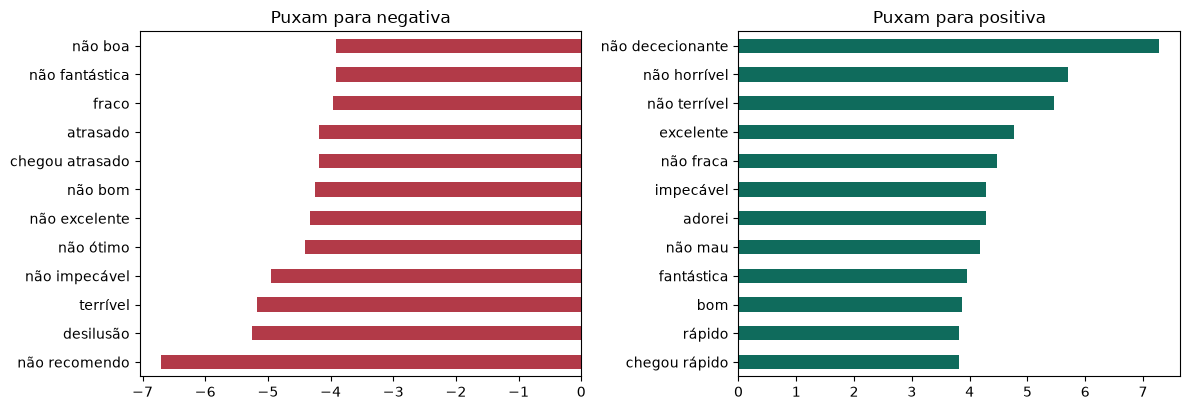

Peso de alguns n-gramas com negação:
{'bom': 3.87, 'não bom': -4.25, 'mau': -3.54, 'não mau': 4.17, 'excelente': 4.77, 'não excelente': -4.32}


In [14]:
# Executar esta célula

melhor = modelos["TF-IDF + trigramas + stopwords"]
nomes = melhor[0].get_feature_names_out()
pesos = pd.Series(melhor[-1].coef_[0], index=nomes).sort_values()

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
pesos.head(12).plot.barh(ax=axs[0], color="#B23A48", title="Puxam para negativa")
pesos.tail(12).plot.barh(ax=axs[1], color="#0F6B5C", title="Puxam para positiva")
plt.tight_layout()
plt.show()
print("Peso de alguns n-gramas com negação:")
print(pesos.reindex(["bom", "não bom", "mau", "não mau", "excelente", "não excelente"]).dropna().round(2).to_dict())

Os pesos mostram as negações aprendidas: «não horrível», «não dececionante» e «não mau» puxam para **positiva**, enquanto «não bom», «não ótimo» e «não recomendo» puxam para **negativa**. É esta interpretabilidade que torna a regressão logística tão útil em texto: dá para explicar cada decisão.

### 5.3 Os erros e textos novos

Os erros mostram onde o modelo tem dificuldade. E vale a pena experimentar frases nossas, sobretudo as difíceis.


In [15]:
# Executar esta célula

previsto = melhor.predict(X_teste)
erros = X_teste[previsto != y_teste]
print(f"{len(erros)} erros em {len(X_teste)}. Alguns:")
for indice, texto in erros.head(6).items():
    print(f"  [rótulo: {'positiva' if y_teste[indice] else 'negativa'}] {texto}")

novos = ["A entrega foi rápida e o produto é excelente!",
         "Não gostei nada, o material é fraco.",
         "O preço não é mau.",
         "O produto não é bom.",
         "Esperava mais, mas o atendimento foi impecável."]
prob = melhor.predict_proba(novos)[:, 1]
print("\nTextos novos (probabilidade de ser positiva):")
for texto, p in zip(novos, prob):
    print(f"  {p:5.0%}  {texto}")

22 erros em 500. Alguns:
  [rótulo: positiva] É a segunda vez que compro, a entrega não foi péssima, mas a qualidade foi mesmo horrível e adorei.
  [rótulo: positiva] Usei durante um mês. A entrega não está impecável.
  [rótulo: positiva] Comprei na promoção, mas o material foi fraco, mas o preço é perfeito, recomendo...
  [rótulo: positiva] Comprei para oferecer, mas nunca mais compro e recomendo, a embalagem é perfeita.
  [rótulo: positiva] Adorei e o material está ótimo, mas foi uma perda de tempo.
  [rótulo: positiva] O atendimento está perfeito, o produto é bastante horrível e a embalagem foi mesmo impecável...

Textos novos (probabilidade de ser positiva):
    94%  A entrega foi rápida e o produto é excelente!
     4%  Não gostei nada, o material é fraco.
    67%  O preço não é mau.
    13%  O produto não é bom.
    79%  Esperava mais, mas o atendimento foi impecável.


Alguns erros são **ruído** (rótulos errados no próprio corpus, que nenhum modelo deve acertar); outros são avaliações mistas difíceis. Nos textos novos, repara em palavras que o modelo nunca viu no treino («gostei», «nada», «esperava»): são simplesmente **ignoradas**, porque não estão no vocabulário. É outra limitação do *bag-of-words*: não sabe que «gostei» se parece com «adorei».


## 6. *Embeddings*: vetores densos com significado

### 6.1 A ideia

No *bag-of-words*, cada palavra é uma coordenada separada: «excelente» e «ótimo» são tão diferentes como «excelente» e «péssimo». Um ***embedding*** representa cada palavra por um **vetor denso** e curto (aqui, 16 números), aprendido de forma a que palavras usadas da mesma maneira fiquem **próximas**.

| | *Bag-of-words* / TF-IDF | *Embedding* |
| --- | --- | --- |
| tamanho do vetor de uma palavra | o vocabulário inteiro (milhares) | fixo e pequeno (16 a 1000) |
| valores | quase todos zero (esparso) | todos preenchidos (denso) |
| palavras parecidas | sem relação | vetores próximos |
| como se obtém | contando | **aprendido** por uma rede neuronal |

No PyTorch, uma camada `nn.Embedding(n_palavras, dimensao)` é simplesmente uma **tabela** com um vetor por palavra: recebe o número de cada palavra e devolve o vetor correspondente. Os vetores são parâmetros, ajustados por retropropagação como os pesos de qualquer camada (N3_04).


In [16]:
# Executar esta célula

contagem_treino = Counter(t for texto in X_treino for t in tokenizar(texto))
vocab = {palavra: i + 1 for i, (palavra, c) in enumerate(contagem_treino.most_common()) if c >= 2}   # 0 = desconhecida
print(f"Vocabulário: {len(vocab)} palavras (as que aparecem pelo menos 2 vezes)")


def para_ids(texto: str) -> list[int]:
    return [vocab.get(t, 0) for t in tokenizar(texto)]


tabela = nn.Embedding(len(vocab) + 1, 16)
ids = torch.tensor(para_ids("o produto é excelente"))
print("ids:", ids.tolist(), "→ vetores:", tuple(tabela(ids).shape))

Vocabulário: 94 palavras (as que aparecem pelo menos 2 vezes)
ids: [2, 15, 3, 28] → vetores: (4, 16)


### 6.2 Um classificador com *embeddings*

O modelo mais simples com *embeddings* faz a **média** dos vetores das palavras de cada texto e passa-a por uma camada linear (é a ideia do fastText, do Facebook). O `nn.EmbeddingBag` faz a procura e a média de uma vez; como os textos têm comprimentos diferentes, recebe todos os *ids* do lote seguidos e as posições (*offsets*) onde começa cada texto.


In [17]:
# Executar esta célula

def lote(textos: list[str]) -> tuple[torch.Tensor, torch.Tensor]:
    sequencias = [torch.tensor(para_ids(t)) for t in textos]
    inicios = torch.tensor([0] + [len(s) for s in sequencias[:-1]]).cumsum(dim=0)
    return torch.cat(sequencias), inicios


class ClassificadorEmbeddings(nn.Module):
    def __init__(self, n_palavras: int, dimensao: int = 16):
        super().__init__()
        self.embedding = nn.EmbeddingBag(n_palavras, dimensao, mode="mean")
        self.saida = nn.Linear(dimensao, 1)

    def forward(self, ids: torch.Tensor, inicios: torch.Tensor) -> torch.Tensor:
        return self.saida(self.embedding(ids, inicios)).squeeze(1)


torch.manual_seed(0)
modelo_emb = ClassificadorEmbeddings(len(vocab) + 1)
otimizador = torch.optim.Adam(modelo_emb.parameters(), lr=0.01)
perda_fn = nn.BCEWithLogitsLoss()
textos_treino = list(X_treino)
y_t = torch.tensor(y_treino.to_numpy(), dtype=torch.float32)

for epoca in range(30):
    modelo_emb.train()
    ordem = torch.randperm(len(textos_treino))
    for i in range(0, len(ordem), 64):
        idx = ordem[i:i + 64]
        ids, inicios = lote([textos_treino[j] for j in idx])
        perda = perda_fn(modelo_emb(ids, inicios), y_t[idx])
        otimizador.zero_grad()
        perda.backward()
        otimizador.step()

modelo_emb.eval()
with torch.no_grad():
    ids, inicios = lote(list(X_teste))
    exat_emb = ((modelo_emb(ids, inicios) > 0).numpy() == y_teste.to_numpy()).mean()
exatidoes["embeddings (média)"] = exat_emb
print(f"Exatidão no teste com embeddings: {exat_emb:.1%} "
      f"(bag-of-words: {exatidoes['bag-of-words']:.1%})")

Exatidão no teste com embeddings: 84.8% (bag-of-words: 83.6%)


A exatidão fica ao nível do *bag-of-words*, e por uma boa razão: **fazer a média** dos vetores também **ignora a ordem** das palavras. A vantagem dos *embeddings* está noutro sítio: no que os vetores aprenderam.

### 6.3 Que palavras ficaram próximas?

Medimos a proximidade com a **semelhança do cosseno** (1 = mesma direção, 0 = sem relação, −1 = opostas):


In [18]:
# Executar esta célula

vetores = modelo_emb.embedding.weight.detach().numpy()
normalizados = vetores / np.linalg.norm(vetores, axis=1, keepdims=True)
palavra_de = {i: p for p, i in vocab.items()}


def vizinhas(palavra: str, k: int = 5) -> list[str]:
    semelhanca = normalizados @ normalizados[vocab[palavra]]
    return [palavra_de[i] for i in np.argsort(-semelhanca) if i in palavra_de and i != vocab[palavra]][:k]


for palavra in ["excelente", "péssimo", "atrasado", "recomendo"]:
    print(f"{palavra:<10} → {vizinhas(palavra)}")

excelente  → ['voltarei', 'cêntimo', 'adorei', 'a', 'cada']
péssimo    → ['arrependido', 'veio', 'atrasado', 'material', 'mau']
atrasado   → ['arrependido', 'mais', 'reembolso', 'mau', 'mal']
recomendo  → ['vale', 'promoção', 'ótimo', 'comprar', 'bem']


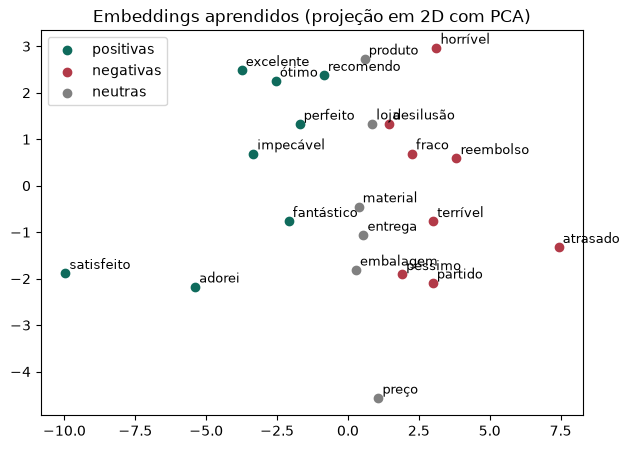

In [19]:
# Executar esta célula

positivas = ["excelente", "ótimo", "fantástico", "perfeito", "adorei", "recomendo", "impecável", "satisfeito"]
negativas = ["péssimo", "horrível", "terrível", "fraco", "atrasado", "partido", "reembolso", "desilusão"]
neutras = ["entrega", "produto", "preço", "embalagem", "loja", "material"]
escolhidas = positivas + negativas + neutras
coordenadas = PCA(n_components=2).fit_transform(vetores[[vocab[p] for p in escolhidas]])

plt.figure(figsize=(7, 5))
for grupo, cor, nome in [(positivas, "#0F6B5C", "positivas"), (negativas, "#B23A48", "negativas"), (neutras, "gray", "neutras")]:
    idx = [escolhidas.index(p) for p in grupo]
    plt.scatter(coordenadas[idx, 0], coordenadas[idx, 1], color=cor, label=nome)
    for i in idx:
        plt.annotate(escolhidas[i], coordenadas[i], fontsize=9, xytext=(3, 3), textcoords="offset points")
plt.legend()
plt.title("Embeddings aprendidos (projeção em 2D com PCA)")
plt.show()

Os vetores separaram-se pelo **sentimento**: as palavras positivas de um lado, as negativas do outro, as neutras no meio. Ninguém disse à rede que «péssimo» e «horrível» são parecidos; ela descobriu-o porque aparecem nos mesmos contextos e têm o mesmo efeito no rótulo.

Repara que estes *embeddings* só aprenderam o que interessa **para esta tarefa** (o sentimento). *Embeddings* treinados em milhares de milhões de palavras, como os do **word2vec** (Mikolov et al., 2013), captam relações muito mais ricas: o exemplo famoso é que o vetor de «rei» − «homem» + «mulher» fica perto de «rainha». Esses vetores pré-treinados podem ser descarregados e reutilizados.

**Experimenta:** procura as vizinhas de outras palavras («rápido», «caro», «embalagem»). Fazem sentido?


In [20]:
# Executar esta célula

# Utiliza esta célula para as tuas experiências

## 7. Opcional: *transformers*

### 7.1 A ideia: atenção ao contexto

Os métodos anteriores têm a mesma fraqueza: cada palavra tem **um só** significado, seja qual for o contexto. Em «o banco do jardim» e «o banco fechou a conta», «banco» teria o mesmo vetor. E a ordem das palavras perde-se quase toda.

Os ***transformers*** (Vaswani et al., 2017, «*Attention is all you need*») resolvem isto com o mecanismo de **atenção**: para calcular o vetor de cada palavra, a rede olha para **todas as outras palavras do texto** e decide quanto peso dar a cada uma. Em «a entrega não foi boa», o vetor de «boa» é influenciado pelo «não». Empilhando muitas camadas de atenção, treinadas em enormes quantidades de texto, obtêm-se modelos que captam gramática, contexto e muito conhecimento do mundo.

São *transformers* o BERT (2018), os modelos GPT, o Claude e praticamente todos os grandes modelos de linguagem (LLM) atuais. Trabalham com ***tokens* de subpalavras**: as palavras raras são partidas em pedaços mais frequentes, o que lhes permite lidar com qualquer palavra, mesmo uma que nunca viram (a célula seguinte mostra a divisão de uma frase).

### 7.2 Usar um modelo pré-treinado

Treinar um *transformer* de raiz exige enormes quantidades de dados e de cálculo. Na prática, usam-se **modelos pré-treinados**, disponíveis na plataforma [Hugging Face](https://huggingface.co/models), através da biblioteca `transformers`. A função `pipeline` carrega o modelo e o *tokenizer* e trata de tudo.

Esta secção precisa de **Internet** para descarregar o modelo (cerca de 500 MB na primeira vez) e da biblioteca `transformers`, que já vem no Colab (no teu computador: `python -m pip install transformers`). Usamos um modelo **multilingue** de análise de sentimento, que funciona em português **sem ter sido treinado nas nossas avaliações**. Se não estiver disponível, a célula avisa e não faz nada.


In [21]:
# Executar esta célula

MODELO = "lxyuan/distilbert-base-multilingual-cased-sentiments-student"
frases = novos + ["A entrega não foi boa.", "O produto não é nada mau, recomendo."]
try:
    from transformers import AutoTokenizer, pipeline
    tokenizer = AutoTokenizer.from_pretrained(MODELO)
    print("Tokens de subpalavras:", tokenizer.tokenize("O material é dececionante"))
    classificador = pipeline("sentiment-analysis", model=MODELO)
    resultados_tf = classificador(frases)
    tf_disponivel = True
except Exception as erro:                              # sem Internet ou sem a biblioteca transformers
    tf_disponivel = False
    print(f"Modelo transformer não disponível ({type(erro).__name__}). Esta secção é opcional: podes continuar.")

if tf_disponivel:
    prob_lr = melhor.predict_proba(frases)[:, 1]
    print(f"\n{'texto':<52}{'TF-IDF (melhor)':>20}{'transformer':>22}")
    for texto, p, r in zip(frases, prob_lr, resultados_tf):
        print(f"{texto:<52}{p:>19.0%} pos.{r['label']:>14} ({r['score']:.0%})")

Modelo transformer não disponível (ModuleNotFoundError). Esta secção é opcional: podes continuar.


Um modelo pré-treinado entende frases e palavras que nunca viu nas nossas avaliações, porque aprendeu a língua com milhões de textos. Mas também tem custos: é milhares de vezes maior do que a regressão logística, mais lento, e não foi ajustado ao vocabulário da loja. Na prática, o caminho habitual é **afinar** (*fine-tuning*) um modelo pré-treinado com os dados do problema, ou, para muitas tarefas, usar diretamente um LLM com instruções bem escritas.

> **A lição do N3_05 continua válida:** compara sempre com um modelo simples. Para classificar avaliações de uma loja, uma regressão logística com TF-IDF e n-gramas pode ser suficiente, e corre em milissegundos.


## 8. Experimenta

### Exercício 1 – O «não» como *stopword*

Treina o melhor modelo («TF-IDF + trigramas + stopwords») duas vezes: com a lista `STOPWORDS` da secção 2.2 e com a mesma lista **mais** a palavra «não» (usa o argumento `stop_words=` do `TfidfVectorizer`, com uma lista). Compara a exatidão no teste e a probabilidade que cada modelo dá a «O produto não é bom.».


In [22]:
# Executar esta célula

# Escreve aqui o código do exercício 1

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for nome, lista in [("sem «não» nas stopwords", sorted(STOPWORDS)), ("com «não» nas stopwords", sorted(STOPWORDS | {"não"}))]:
    m = make_pipeline(TfidfVectorizer(token_pattern=r"\w+", ngram_range=(1, 3), stop_words=lista),
                      LogisticRegression(C=10, max_iter=2000)).fit(X_treino, y_treino)
    p = m.predict_proba(["O produto não é bom."])[0, 1]
    print(f"{nome:<26} exatidão {m.score(X_teste, y_teste):.1%} | «O produto não é bom.» positiva com {p:.0%}")
# Sem o «não», a frase fica «produto bom», e o modelo deixa de conseguir ver a negação.
```

</details>


### Exercício 2 – Tamanho do vocabulário

O argumento `min_df` do `TfidfVectorizer` ignora os termos que aparecem em menos de `min_df` textos. Para `min_df` = 1, 2, 5, 10 e 20, mostra o tamanho do vocabulário (com trigramas) e a exatidão no teste. Há um compromisso?


In [23]:
# Executar esta célula

# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for min_df in [1, 2, 5, 10, 20]:
    m = make_pipeline(TfidfVectorizer(token_pattern=r"\w+", ngram_range=(1, 3), min_df=min_df),
                      LogisticRegression(C=10, max_iter=2000)).fit(X_treino, y_treino)
    print(f"min_df={min_df:<3} vocabulário {len(m[0].vocabulary_):>6} | exatidão {m.score(X_teste, y_teste):.1%}")
# Cortar os termos raros reduz muito o vocabulário (e a memória) com pouca perda,
# até certo ponto: com min_df alto, perdem-se n-gramas úteis.
```

</details>


### Exercício 3 – Um classificador para usar

Escreve uma função `sentimento(texto)` que use o melhor modelo da secção 5 e devolva uma frase como `"positiva (87 %)"`. Testa-a com cinco avaliações escritas por ti, incluindo pelo menos uma negação e uma avaliação mista.


In [24]:
# Executar esta célula

# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
def sentimento(texto: str) -> str:
    p = melhor.predict_proba([texto])[0, 1]
    return f"positiva ({p:.0%})" if p >= 0.5 else f"negativa ({1 - p:.0%})"


for texto in ["Adorei a embalagem, muito cuidada.",
              "A aplicação é péssima e a entrega chegou atrasada.",
              "O tamanho não é o problema, o problema é o preço horrível.",
              "O atendimento foi fantástico, mas o produto veio partido.",
              "Não é mau, recomendo."]:
    print(f"{sentimento(texto):<16} {texto}")
```

</details>


## Verifica o que aprendeste

1. O que é tokenizar, e porque se põe o texto em minúsculas?
2. Porque é que, em análise de sentimento, não se deve tirar o «não» das *stopwords*?
3. O que é o *bag-of-words*, e que informação perde? Como ajudam os n-gramas?
4. O que mede o IDF, e porque é que as palavras muito frequentes ficam com peso baixo no TF-IDF?
5. Porque se guardam as matrizes de texto em formato esparso?
6. O que acontece a uma palavra nova, que não estava no vocabulário do treino?
7. O que é um *embedding*, e o que mostra a semelhança do cosseno entre dois *embeddings*?
8. Que limitação comum aos métodos anteriores resolvem os *transformers*, e com que mecanismo?

<details>
<summary><b>Ver respostas</b></summary>

1. Partir o texto em unidades (*tokens*), normalmente palavras. As minúsculas fazem com que «Adorei» e «adorei» sejam o mesmo *token*.
2. Porque inverte o sentido da frase: sem ele, «não é bom» passa a «bom».
3. Representa cada texto pelas contagens das palavras do vocabulário. Perde a ordem: «não é bom, é mau» e «não é mau, é bom» ficam iguais. Os n-gramas contam também sequências de 2 ou 3 palavras, preservando alguma ordem local.
4. Mede a raridade de uma palavra no corpus. Palavras que aparecem em quase todos os textos não ajudam a distingui-los, por isso o IDF (e o peso) é baixo.
5. Porque cada texto usa só uma pequena parte do vocabulário: quase todos os valores são zero, e guardar só os outros poupa muita memória.
6. É ignorada: não tem coluna no *bag-of-words*/TF-IDF, nem vetor no *embedding* (fica como «desconhecida»).
7. Um vetor denso e curto que representa uma palavra, aprendido por uma rede. A semelhança do cosseno mede se dois vetores apontam na mesma direção, ou seja, se as palavras são usadas de forma parecida.
8. Cada palavra tinha um só significado, independente do contexto, e a ordem perdia-se. Os *transformers* usam a **atenção**: o vetor de cada palavra depende de todas as outras palavras do texto.

</details>

## Leitura recomendada

- Jurafsky, D. e Martin, J. H. *[Speech and Language Processing](https://web.stanford.edu/~jurafsky/slp3/)* (3.ª ed., versão provisória gratuita em linha). A referência do PLN: classificação de texto, TF-IDF, *embeddings* e *transformers*.
- [Guia do scikit-learn: extração de atributos de texto](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction).
- Mikolov, T., Chen, K., Corrado, G. e Dean, J. (2013). «[Efficient estimation of word representations in vector space](https://arxiv.org/abs/1301.3781)». O artigo do word2vec.
- Vaswani, A. et al. (2017). «[Attention is all you need](https://arxiv.org/abs/1706.03762)». *NeurIPS 2017*. O artigo dos *transformers*.
- Alammar, J. «[The Illustrated Transformer](https://jalammar.github.io/illustrated-transformer/)». Uma explicação visual da atenção.
- [Curso de PLN da Hugging Face](https://huggingface.co/learn/llm-course). Gratuito; como usar e afinar modelos pré-treinados.
- Tunstall, L., von Werra, L. e Wolf, T. (2022). *Natural Language Processing with Transformers* (ed. revista). Sebastopol: O'Reilly Media.
- **Módulos relacionados:** N3_05 (PyTorch) e N3_06 (redes convolucionais).
